# EDA

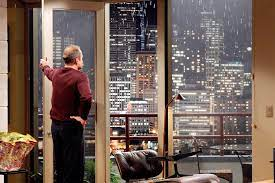

In [2]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

df_house = pd.read_csv("cleandataset.csv")
df_house.head()

available = sorted({f.name for f in font_manager.fontManager.ttflist})
print(available)
print("Verdana" in available)

['AIGDT', 'AMGDT', 'AcadEref', 'Agency FB', 'Algerian', 'AmdtSymbols', 'Arial', 'Arial Black', 'Arial Narrow', 'Arial Rounded MT Bold', 'Arial Unicode MS', 'Artifakt Element', 'Artifakt Element Black', 'Artifakt Element Book', 'Artifakt Element Extra Bold', 'Artifakt Element Extra Light', 'Artifakt Element Hair', 'Artifakt Element Heavy', 'Artifakt Element Light', 'Artifakt Element Medium', 'Artifakt Element Semi Bold', 'Artifakt Element Thin', 'Bahnschrift', 'BankGothic Lt BT', 'BankGothic Md BT', 'Baskerville Old Face', 'Bauhaus 93', 'Bell MT', 'Berlin Sans FB', 'Berlin Sans FB Demi', 'Bernard MT Condensed', 'Blackadder ITC', 'Bodoni MT', 'Bodoni MT Black', 'Bodoni MT Condensed', 'Bodoni MT Poster Compressed', 'Book Antiqua', 'Bookman Old Style', 'Bookshelf Symbol 7', 'Bradley Hand ITC', 'Britannic Bold', 'Broadway', 'Brush Script MT', 'Calibri', 'Calibri Light', 'Californian FB', 'Calisto MT', 'Cambria', 'Cambria Math', 'Candara', 'Candara Light', 'Castellar', 'Centaur', 'Century', 

## General data review:
### King County house sales; May 2014 to May 2015


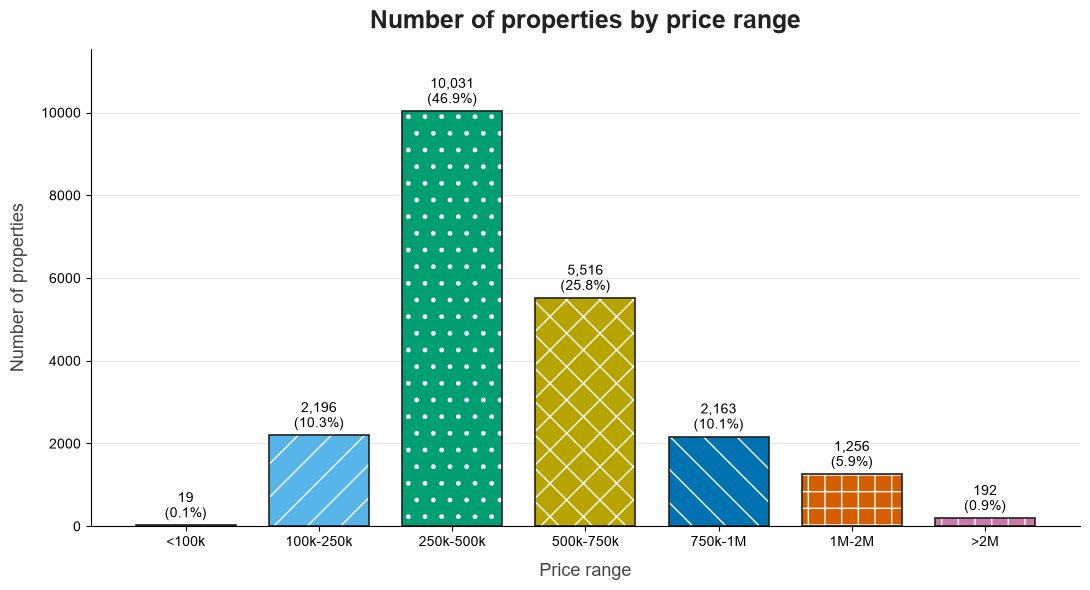

In [3]:

plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

# Price segments
bins = [0, 100_000, 250_000, 500_000, 750_000, 1_000_000, 2_000_000, float("inf")]
labels = ["<100k", "100k-250k", "250k-500k", "500k-750k", "750k-1M", "1M-2M", ">2M"]
df_unique = df_house.sort_values("date").drop_duplicates(subset="id", keep="last").copy()
df_unique["price_range"] = pd.cut(df_unique["price"], bins=bins, labels=labels, right=False)

counts = df_unique["price_range"].value_counts().reindex(labels)
share = counts / counts.sum() * 100

# Okabe-Ito colorblind-safe palette; darker tones so white texture stays visible
colors = ["#E69F00", "#56B4E9", "#009E73", "#B8A400", "#0072B2", "#D55E00", "#CC79A7"]
# sparse patterns (single characters = wide spacing, much less busy)
hatches = ["", "/", ".", "x", "\\", "+", "|"]

plt.rcParams["hatch.linewidth"] = 1.0  
     # thin hatch lines

fig, ax = plt.subplots(figsize=(11, 6))

# layer 1: colored bars with WHITE hatch (hatch color = edgecolor)
bars = ax.bar(labels, counts, color=colors, edgecolor="white", linewidth=0, width=0.75)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
    bar.set_edgecolor("white")

# layer 2: thin dark outline on top, so every bar stays clearly defined
ax.bar(labels, counts, fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

# value labels on top of each bar
for bar, n, pct in zip(bars, counts, share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.01,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

ax.set_title("Number of properties by price range",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Price range",
              fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties",
              fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

## H1: Bedrooms and price (5-6 vs 3-4 bedrooms)


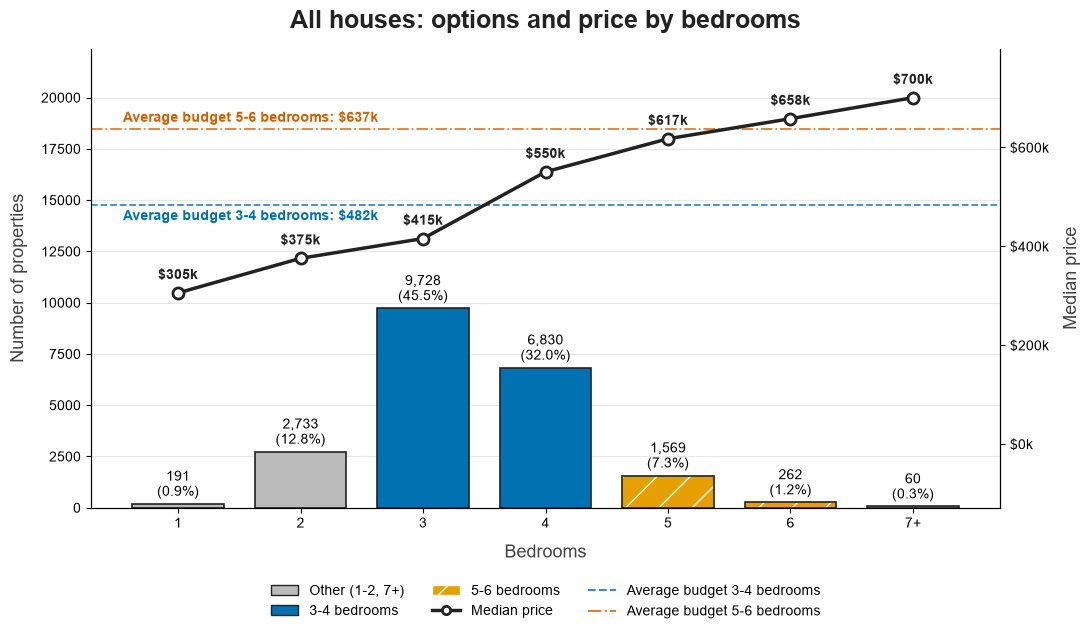

In [4]:

plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

df_all = df_unique.copy()
df_all["bed_group"] = df_all["bedrooms"].clip(upper=7).astype(int)   # 7 = "7+"

by_bed = df_all.groupby("bed_group").agg(n=("price", "size"),
                                         median_price=("price", "median"))
x = [f"{b}+" if b == 7 else str(b) for b in by_bed.index]
share = by_bed["n"] / by_bed["n"].sum() * 100

# categories: 3-4 (blue), 5-6 (orange, pattern), others grey
def style(b):
    if 3 <= b <= 4:
        return "#0072B2", ""
    if 5 <= b <= 6:
        return "#E69F00", "/"
    return "#BBBBBB", ""

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(x, by_bed["n"], width=0.75, linewidth=0,
              color=[style(b)[0] for b in by_bed.index])
for bar, b in zip(bars, by_bed.index):
    hatch = style(b)[1]
    if hatch:
        bar.set_hatch(hatch)
        bar.set_edgecolor("white")
ax.bar(x, by_bed["n"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

for bar, n, pct in zip(bars, by_bed["n"], share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + by_bed["n"].max() * 0.02,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

# bars use only the lower part of the chart
ax.set_ylim(0, by_bed["n"].max() * 2.3)

# second axis: price line in the upper part (limits adapt to the data)
ax2 = ax.twinx()
mn, mx = by_bed["median_price"].min(), by_bed["median_price"].max()
span = mx - mn
ax2.set_ylim(mn - span * 1.1, mx + span * 0.25)

# average budget needed = average of the median prices per group
avg_34 = by_bed.loc[(by_bed.index >= 3) & (by_bed.index <= 4), "median_price"].mean()
avg_56 = by_bed.loc[(by_bed.index >= 5) & (by_bed.index <= 6), "median_price"].mean()

ax2.axhline(avg_34, color="#0072B2", linestyle="--", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_34 - span * 0.02, f"Average budget 3-4 bedrooms: ${avg_34/1000:.0f}k",
         ha="left", va="top", fontsize=10, fontweight="bold", color="#0072B2")

ax2.axhline(avg_56, color="#D55E00", linestyle="-.", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_56 + span * 0.02, f"Average budget 5-6 bedrooms: ${avg_56/1000:.0f}k",
         ha="left", va="bottom", fontsize=10, fontweight="bold", color="#D55E00")

ax2.plot(x, by_bed["median_price"], color="#222222", marker="o", markersize=8,
         markerfacecolor="white", markeredgewidth=2, linewidth=2.5, zorder=3)
for xi, med in zip(x, by_bed["median_price"]):
    ax2.annotate(f"${med/1000:.0f}k", (xi, med), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=10, fontweight="bold",
                 color="#222222")
# hide negative tick labels on the price axis
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k" if v >= 0 else ""))
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("All houses: options and price by bedrooms",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# legend below the chart, two rows
legend_items = [
    Patch(facecolor="#BBBBBB", edgecolor="#222222", label="Other (1-2, 7+)"),
    Patch(facecolor="#0072B2", edgecolor="#222222", label="3-4 bedrooms"),
    Patch(facecolor="#E69F00", edgecolor="white", hatch="/", label="5-6 bedrooms"),
    Line2D([0], [0], color="#222222", marker="o", markerfacecolor="white",
           markeredgewidth=2, linewidth=2.5, label="Median price"),
    Line2D([0], [0], color="#0072B2", linestyle="--", alpha=0.8,
           label="Average budget 3-4 bedrooms"),
    Line2D([0], [0], color="#D55E00", linestyle="-.", alpha=0.8,
           label="Average budget 5-6 bedrooms"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=3, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

## What can a low budget buy?


In [5]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

budget = df_unique[df_unique["price"].between(100_000, 250_000)].copy()
budget["bed_group"] = budget["bedrooms"].clip(upper=7).astype(int)   # 7 = "7+"

budget["price_band"] = pd.cut(budget["price"], bins=[100_000, 200_000, 250_001],
                              labels=["$100k-200k", "$200k-250k"], right=False)

check = pd.crosstab(budget["bed_group"], budget["price_band"], margins=True, margins_name="Total")
check.index = [f"{b}+" if b == 7 else str(b) for b in check.index[:-1]] + ["Total"]
print(check)

price_band  $100k-200k  $200k-250k  Total
1                   30          31     61
2                  241         317    558
3                  370         978   1348
4                   57         251    308
5                   10          31     41
6                    1           6      7
Total              709        1614   2323


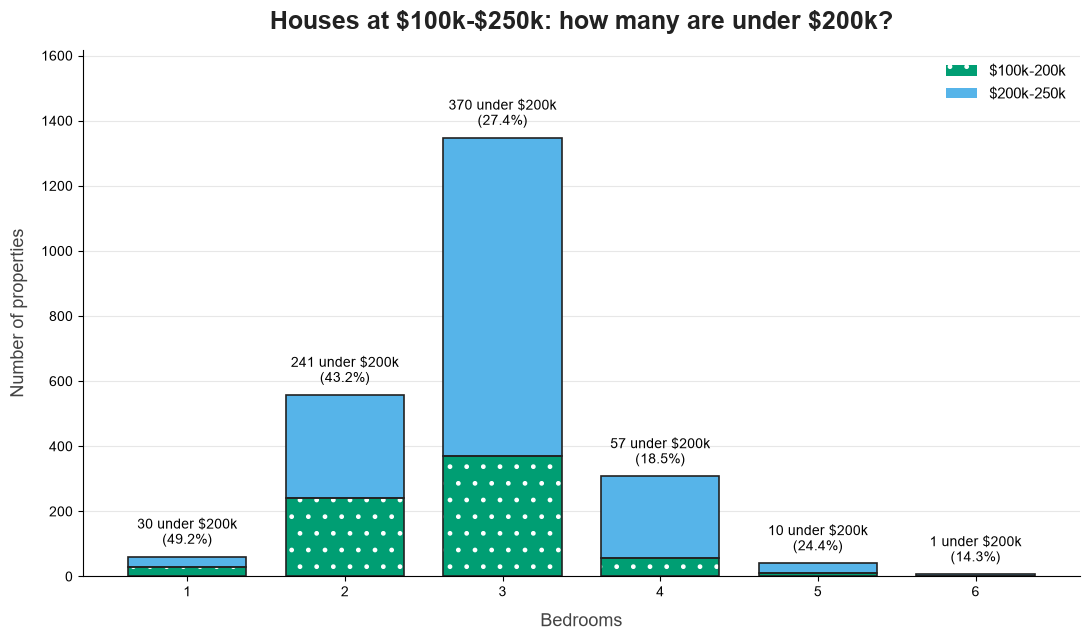

In [6]:
bands = (budget.groupby(["bed_group", "price_band"], observed=False).size()
         .unstack(fill_value=0))
x = [f"{b}+" if b == 7 else str(b) for b in bands.index]
total = bands.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 6.5))

# bottom: $100k-200k (green, white dots)
low = ax.bar(x, bands["$100k-200k"], color="#009E73", width=0.75, linewidth=0,
             label="$100k-200k")
for bar in low:
    bar.set_hatch(".")
    bar.set_edgecolor("white")

# top: $200k-250k (sky blue)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], color="#56B4E9",
       width=0.75, linewidth=0, label="$200k-250k")

# dark outlines on both parts
ax.bar(x, bands["$100k-200k"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], fill=False,
       edgecolor="#222222", linewidth=1.2, width=0.75)

# label: houses under $200k and their share
for i, (n_low, t) in enumerate(zip(bands["$100k-200k"], total)):
    pct = n_low / t * 100 if t else 0
    ax.text(i, t + total.max() * 0.02, f"{n_low:,} under $200k\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10)

ax.set_title("Houses at $100k-$250k: how many are under $200k?",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, total.max() * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

1290 properties
zipcode
98001    6.96
98002    6.64
98003    7.09
98006    6.50
98008    7.00
98010    6.27
98014    6.00
98019    5.80
98022    6.79
98023    7.10
98024    5.00
98027    5.67
98028    6.25
98030    6.94
98031    7.00
98032    7.05
98034    7.00
98038    6.86
98042    6.81
98045    6.80
98052    6.00
98055    6.62
98056    6.21
98058    6.71
98059    6.64
98065    5.50
98070    6.00
98072    6.00
98077    7.00
98092    7.12
98103    6.00
98106    6.59
98108    7.10
98109    7.00
98116    7.00
98118    6.61
98125    6.33
98126    6.33
98133    6.78
98136    6.00
98144    7.50
98146    6.38
98148    7.14
98155    6.75
98166    6.33
98168    6.56
98178    6.46
98188    6.83
98198    6.87
Name: grade, dtype: float64


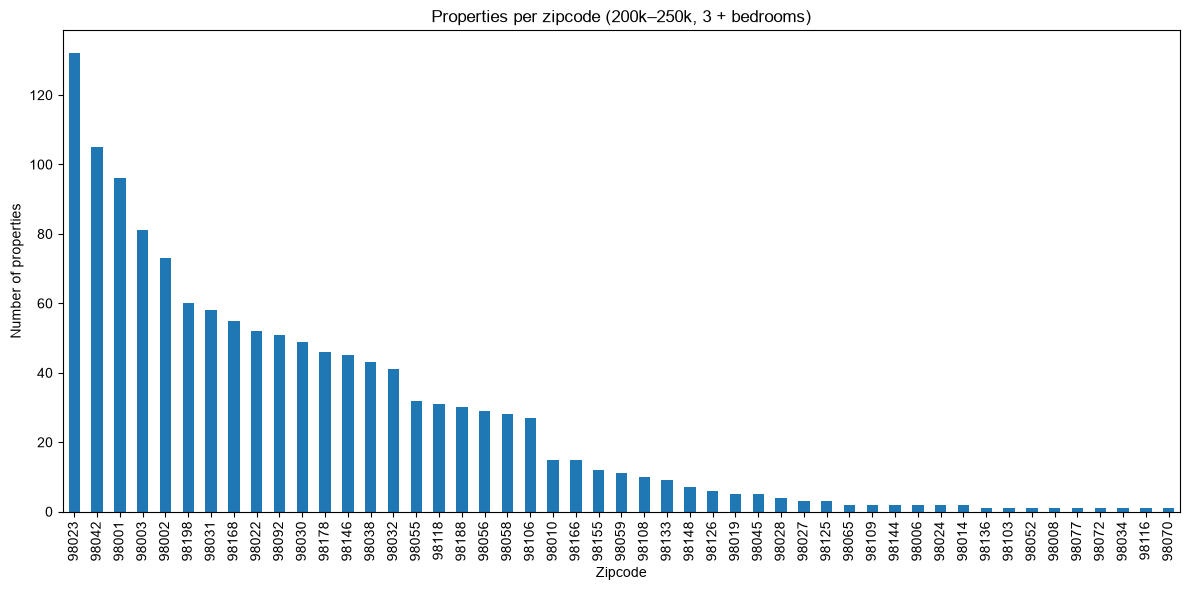

In [7]:

# 1. Filter: price between 100k and 250k, at least 5 bedrooms
df_filtered = df_house[
    (df_house["price"].between(200_000, 250_000)) &
    (df_house["bedrooms"] >= 3)
]
print(len(df_filtered), "properties")

# 2. Mean grade per zipcode
mean_grade = df_filtered.groupby("zipcode")["grade"].mean().round(2)
print(mean_grade)

# 3. Number of properties per zipcode
zip_counts = df_filtered["zipcode"].value_counts()

zip_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Properties per zipcode (200k–250k, 3 + bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Number of properties")
plt.xticks(rotation=90)
plt.tight_layout()
#plt.show()

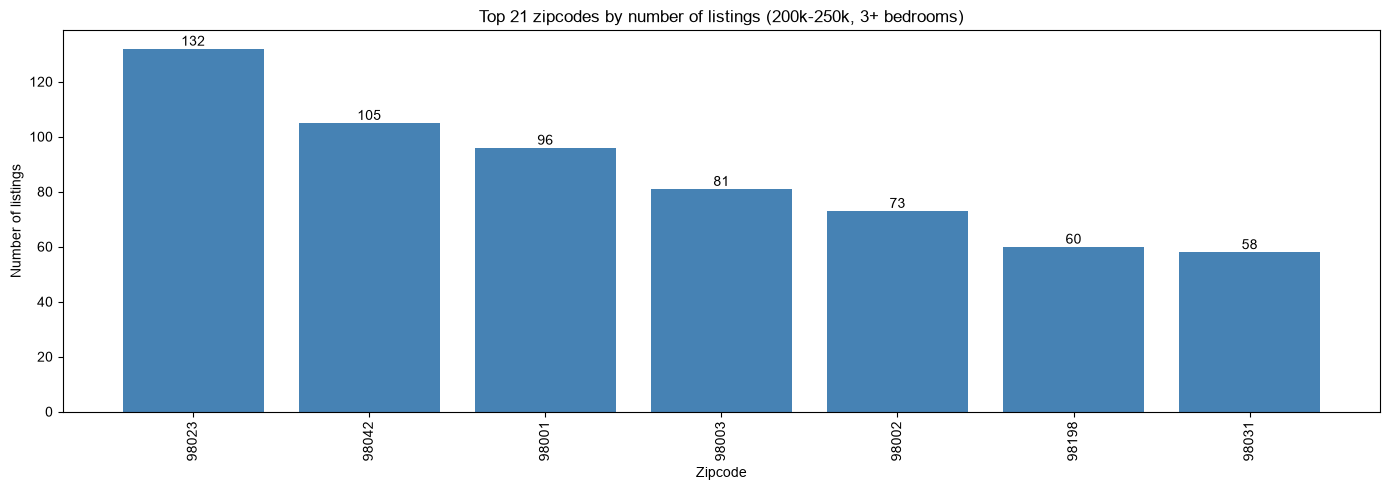

In [8]:
df = pd.read_csv("cleandataset.csv")

MIN_BEDROOMS = 3  # adjust the bedroom filter here

# Filter: price 160k-250k and at least MIN_BEDROOMS bedrooms
df_f = df[df["price"].between(200_000, 250_000) & (df["bedrooms"] >= MIN_BEDROOMS)]

# The 21 zipcodes with the most listings
top21_counts = df_f["zipcode"].value_counts().head(7)

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(top21_counts.index.astype(str), top21_counts.values, color="steelblue")
for bar, n in zip(bars, top21_counts.values):  # count above each bar
    ax.text(bar.get_x() + bar.get_width() / 2, n, str(n), ha="center", va="bottom")
ax.set_title(f"Top 21 zipcodes by number of listings (200k-250k, {MIN_BEDROOMS}+ bedrooms)")
ax.set_xlabel("Zipcode")
ax.set_ylabel("Number of listings")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


         n_listings  social_score  mean_condition  mean_grade  \
zipcode                                                         
98023           132          62.5            3.49        7.10   
98042           105          64.3            3.81        6.81   
98001            96          59.9            3.50        6.96   
98003            81          61.4            3.40        7.09   
98002            73          67.5            3.95        6.64   
98198            60          63.4            3.37        6.87   
98031            58          65.2            3.60        7.00   

         condition_all_zip  grade_all_zip  
zipcode                                    
98023                 3.39           7.58  
98042                 3.52           7.42  
98001                 3.34           7.30  
98003                 3.37           7.54  
98002                 3.74           6.69  
98198                 3.44           7.10  
98031                 3.50           7.38  


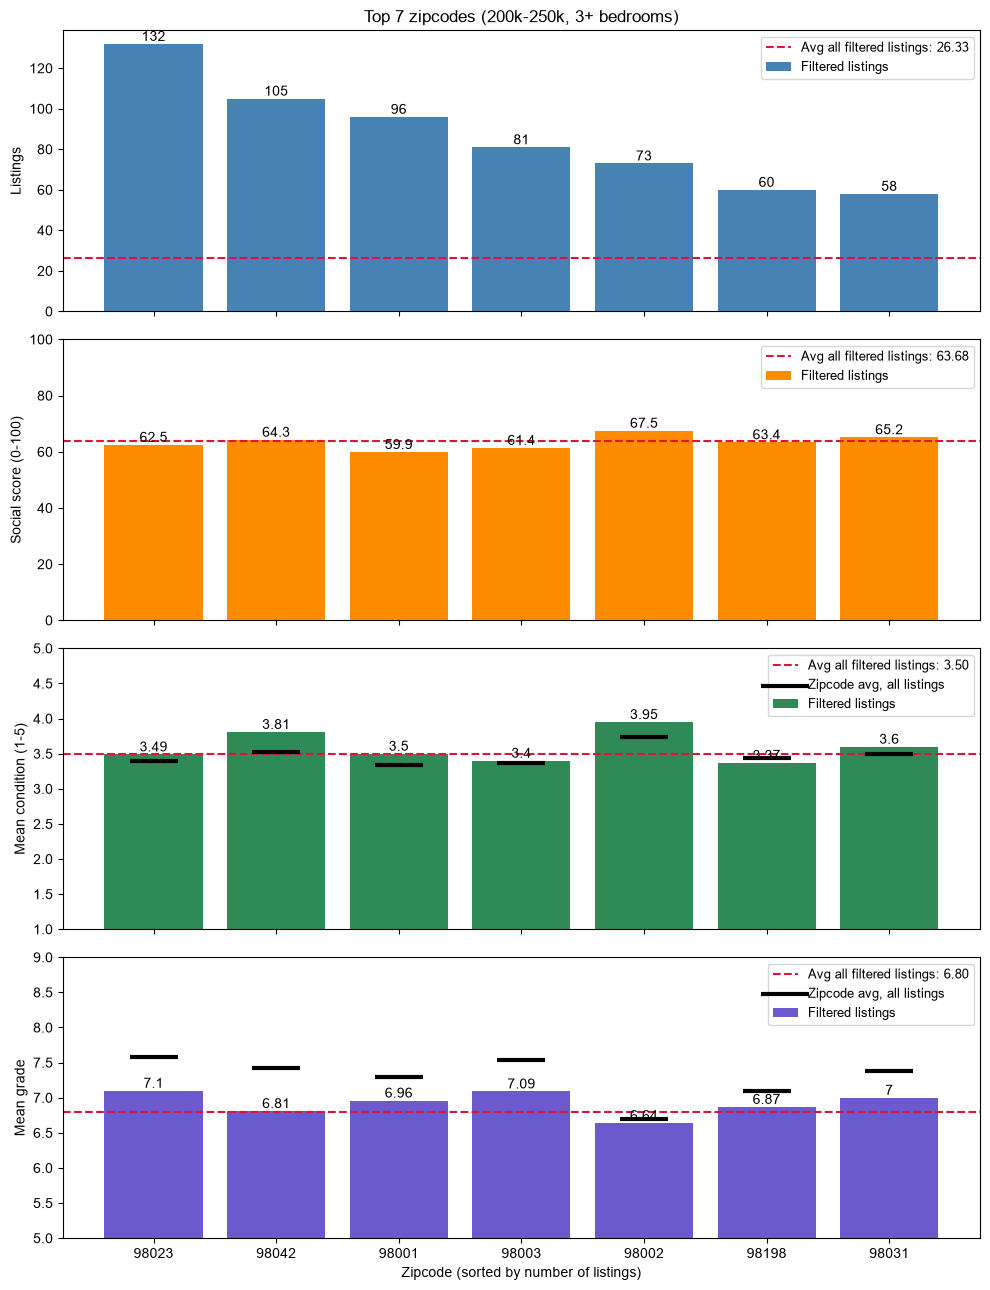

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleandataset.csv")

MIN_BEDROOMS = 3   # bedroom filter
TOP_N = 7          # number of zipcodes to keep

# Social score per zipcode (same definition as 05_data_review), computed on ALL data
zip_lot = df.assign(log_lot15=np.log(df["sqft_lot15"])).groupby("zipcode")["log_lot15"].median()
social_score = (100 * (zip_lot.max() - zip_lot) / (zip_lot.max() - zip_lot.min())).round(1)

# Filter, attach each listing's zipcode social score
df_f = df[df["price"].between(200_000, 250_000) & (df["bedrooms"] >= MIN_BEDROOMS)].copy()
df_f["social_score"] = df_f["zipcode"].map(social_score)

# Keep the TOP_N zipcodes with the most listings
top_zips = df_f["zipcode"].value_counts().head(TOP_N).index

summary = (
    df_f[df_f["zipcode"].isin(top_zips)]
    .groupby("zipcode")
    .agg(
        n_listings=("price", "size"),
        social_score=("social_score", "first"),
        mean_condition=("condition", "mean"),
        mean_grade=("grade", "mean"),
    )
    .round(2)
    .reindex(top_zips)  # keep order: most listings first
)

# Per-zipcode averages over ALL listings (no price / bedroom filter)
zip_all = (
    df[df["zipcode"].isin(top_zips)]
    .groupby("zipcode")
    .agg(mean_condition=("condition", "mean"), mean_grade=("grade", "mean"))
    .round(2)
    .reindex(top_zips)
)
summary["condition_all_zip"] = zip_all["mean_condition"]
summary["grade_all_zip"] = zip_all["mean_grade"]
print(summary)

# Averages across ALL filtered listings (every zipcode)
overall = {
    "n_listings":     df_f["zipcode"].value_counts().mean(),  # avg listings per zipcode
    "social_score":   df_f["social_score"].mean(),
    "mean_condition": df_f["condition"].mean(),
    "mean_grade":     df_f["grade"].mean(),
}

# Plot: one panel per measure
labels = summary.index.astype(str)
panels = [
    ("n_listings",     "Listings",              "steelblue",  None),
    ("social_score",   "Social score (0-100)",  "darkorange", (0, 100)),
    ("mean_condition", "Mean condition (1-5)",  "seagreen",   (1, 5)),
    ("mean_grade",     "Mean grade",            "slateblue",  (5, 9)),
]
zip_all_cols = {"mean_condition": "condition_all_zip", "mean_grade": "grade_all_zip"}

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 13), sharex=True)
for ax, (col, ylabel, color, ylim) in zip(axes, panels):
    bars = ax.bar(labels, summary[col], color=color, label="Filtered listings")
    for bar, v in zip(bars, summary[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:g}", ha="center", va="bottom")

    # Dashed line: average across all filtered listings
    ax.axhline(overall[col], color="crimson", linestyle="--", linewidth=1.5,
               label=f"Avg all filtered listings: {overall[col]:.2f}")

    # Black tick per zipcode: average of ALL listings in that zipcode
    if col in zip_all_cols:
        ax.scatter(labels, summary[zip_all_cols[col]], marker="_", s=1200,
                   linewidths=3, color="black", zorder=3,
                   label="Zipcode avg, all listings")

    ax.legend(loc="upper right", fontsize=9)
    ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)

axes[0].set_title(f"Top {TOP_N} zipcodes (200k-250k, {MIN_BEDROOMS}+ bedrooms)")
axes[-1].set_xlabel("Zipcode (sorted by number of listings)")
plt.tight_layout()
plt.show()

